# IT9002 Lab 5.2: Extracting Organization Locations from Company News

**Unit 05: Sequence Labeling and Information Extraction**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Use spaCy to identify the organizations and locations mentioned in news sentences.
- Extract organization-location pairs with a rule based on the recognized entities.
- Evaluate the precision of an extraction rule on a sample of checked pairs.
- Identify the causes of incorrect pairs and use them to improve the rule.
- Choose the number of topics of a topic model from its coherence and a reading of its topics.

## Data

- **CoNLL-2003** (Tjong Kim Sang and De Meulder, 2003), 578 sentences of Reuters news about companies from 1996 with their gold entity tags, Hugging Face `eriktks/conll2003`, https://huggingface.co/datasets/eriktks/conll2003, annotations free for research use, text under the Reuters Corpus license for research and teaching.

- **BBC News** (Greene and Cunningham, 2006), 2,225 articles of the BBC News website from 2004 and 2005 in 5 categories, http://mlg.ucd.ie/datasets/bbc.html, provided by the authors for non-commercial and research use, article text copyright BBC.

- The course file `company_news.csv` (on Moodle).

- The course file `bbc_news.csv` (on Moodle).

The files `company_news.csv` and `bbc_news.csv` can be downloaded from Moodle. Download them to your computer, then run the cell below. If the files are already available in the runtime, the cell loads them directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

def course_file(name):
    path = next((p for p in (Path(name), Path("data") / name) if p.exists()), None)
    if path is None:
        from google.colab import files
        files.upload()
        path = Path(name)
    return path

news = pd.read_csv(course_file("company_news.csv"))
bbc = pd.read_csv(course_file("bbc_news.csv"))
print(news.shape, bbc.shape)
news.head()

(578, 4) (2225, 3)


,split,row,tokens,ner_tags
0,train,50,Opel AG together with General Motors came in s...,B-ORG I-ORG O O B-ORG I-ORG O O O O O O O O O ...
1,train,78,BORROWER VENANTIUS AB ( SWEDISH NATIONAL MORTG...,O B-ORG I-ORG O B-MISC O O O O
2,train,134,"A spokesman for the group said the meeting "" s...",O O O O O O O O O O O O O O O O B-ORG I-ORG O ...
3,train,182,"The Russians , working for the Aerostan firm i...",O B-MISC O O O O B-ORG O O O B-MISC O O B-LOC ...
4,train,233,KinderCare Learning Centers Inc said on Thursd...,B-ORG I-ORG I-ORG I-ORG O O O O O O O O O O O ...


## Setup

**gensim**, the library used for topic modeling, is not preinstalled in Google Colab. The following cell installs it if it is not already available.

In [2]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("gensim") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim"], check=True)

Imports the libraries and tools required for the lab and displays the installed versions of **pandas**, **spaCy**, `en_core_web_sm`, and gensim.

`en_core_web_sm` is spaCy's small English pipeline, which is downloaded if it is not already installed.

The English stop-word list of **NLTK** is downloaded for the topic model.

In [3]:
import random
import re
import numpy as np
import matplotlib.pyplot as plt
import gensim
import nltk
import spacy
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel
from nltk.corpus import stopwords
from spacy import displacy
from spacy.tokens import Doc
from spacy.training import Example
from spacy.util import fix_random_seed, minibatch

try:
    nlp_spacy = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp_spacy = spacy.load("en_core_web_sm")

nltk.download("stopwords", quiet=True)
print("pandas", pd.__version__, "| spaCy", spacy.__version__, "| en_core_web_sm", nlp_spacy.meta["version"],
      "| gensim", gensim.__version__)

pandas 3.0.2 | spaCy 3.8.16 | en_core_web_sm 3.8.0 | gensim 4.4.0


## 1. Company News Sentences

Each row of `news` contains one sentence as space-separated tokens, with the gold tags of the tokens in the BIO scheme.

`gold_entities()` converts the BIO tags of a sentence into a set of entities, each written as its start position, its end position, and its type. The end position is the position immediately after the last token of the entity.

The gold entities of the first sentence are displayed with their tokens:

In [4]:
def gold_entities(tags):
    entities, start = set(), None
    for k, tag in enumerate(tags + ["O"]):
        if start is not None and tag != "I-" + kind:
            entities.add((start, k, kind))
            start = None
        if tag.startswith("B-"):
            start, kind = k, tag[2:]
    return entities

gold = [gold_entities(tags.split()) for tags in news["ner_tags"]]
tokens = news["tokens"][0].split()
print(news["tokens"][0])
print([(" ".join(tokens[s:e]), kind) for s, e, kind in sorted(gold[0])])

Opel AG together with General Motors came in second place with 49,269 registrations , 16.4 percent of the overall figure .
[('Opel AG', 'ORG'), ('General Motors', 'ORG')]


The gold entities of all 578 sentences are counted by type:

In [5]:
pd.Series([kind for entities in gold for _, _, kind in entities]).value_counts()

ORG     977
LOC     263
MISC    212
PER     143
Name: count, dtype: int64

The sentences contain **977** gold organizations and only **263** gold locations, so many sentences mention an organization without a location.

## 2. Organizations and Locations Identified by spaCy

spaCy processes the sentences with the same tokens as the gold tags, so that its entities and the gold entities refer to the same token positions.

`process(nlp)` constructs a `Doc` from the gold tokens of each sentence, runs the pipeline `nlp` on it, and returns the list of Docs.

The entities that spaCy identifies are counted by label:

In [6]:
def process(nlp):
    return list(nlp.pipe(Doc(nlp.vocab, words=text.split()) for text in news["tokens"]))

docs = process(nlp_spacy)
pd.Series([ent.label_ for doc in docs for ent in doc.ents]).value_counts()

ORG            792
DATE           355
GPE            257
PERSON         223
CARDINAL       185
MONEY          152
NORP           111
PERCENT         73
QUANTITY        30
TIME            19
ORDINAL         17
LOC             13
PRODUCT         11
WORK_OF_ART      9
FAC              6
EVENT            4
Name: count, dtype: int64

spaCy labels countries and cities as GPE, other places such as regions as LOC, and buildings, airports, and roads as FAC.

This lab uses the entities labeled GPE or LOC as the locations of the pairs.

The entities of sentence `495` are displayed with displaCy:

In [7]:
displacy.render(docs[495], style="ent", jupyter=True)

`Tanjung Priok`, a port in Jakarta, is labeled by spaCy as an organization.

`entity_scores()` compares the entities that a pipeline identifies with the gold entities, and calculates entity-level precision, recall, and F1 for organizations, locations, and persons.

spaCy's types are first mapped to the CoNLL-2003 types: `PERSON` to `PER`, `ORG` to `ORG`, and `GPE`, `LOC`, and `FAC` to `LOC`. FAC is scored as a location here, although the pairs do not use it.

In [8]:
TO_CONLL = {"PERSON": "PER", "ORG": "ORG", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC"}

def entity_scores(docs):
    rows = {}
    for kind in ("ORG", "LOC", "PER"):
        predicted = {(i, e.start, e.end) for i, doc in enumerate(docs) for e in doc.ents if TO_CONLL.get(e.label_) == kind}
        reference = {(i, s, e) for i, entities in enumerate(gold) for s, e, k in entities if k == kind}
        correct = len(predicted & reference)
        p, r = correct / max(len(predicted), 1), correct / len(reference)
        rows[kind] = {"precision": p, "recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0}
    return pd.DataFrame(rows).T.round(3)

scores = entity_scores(docs)
scores

,precision,recall,F1
ORG,0.705,0.571,0.631
LOC,0.743,0.779,0.761
PER,0.511,0.797,0.623


The precision, recall, and F1 of each type are displayed in a grouped bar chart:

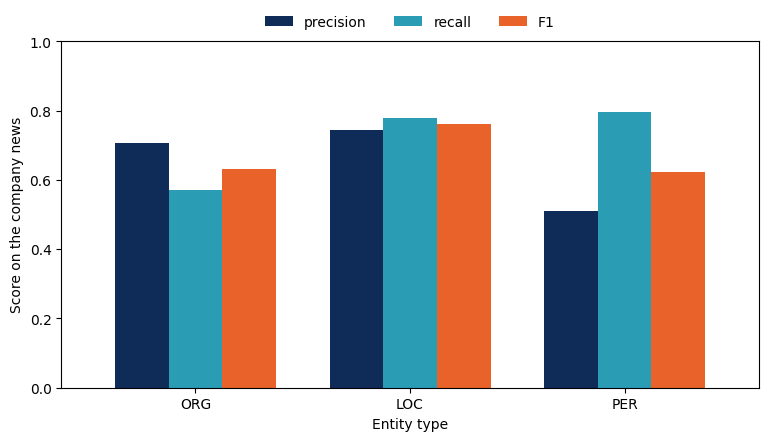

In [9]:
NAVY, TEAL, ORANGE = "#0F2B58", "#2A9DB5", "#E8622A"
ax = scores.plot.bar(figsize=(9, 4.5), width=0.75, color=[NAVY, TEAL, ORANGE], rot=0)
ax.set_xlabel("Entity type")
ax.set_ylabel("Score on the company news")
ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.show()

About 3 in 10 predicted organizations and 1 in 4 predicted locations match no gold entity. A pair formed from these entities is wrong whenever either of its names is wrong.

## 3. Extracting Organization-Location Pairs

This section extracts the relation between an organization and the location where it is based or to which it belongs.

The **starting rule** pairs each organization in a sentence with every location in the same sentence.

`pair_table()` applies the starting rule to all sentences and returns a table with one row for each pair and these columns:

- `sentence`: the row of the sentence in `news`.

- `organization` and `location`: the names of the organization and the location of the pair.

- `org_span` and `loc_span`: the start and end token positions of these names in the sentence.

- `gap`: the number of tokens between the names.

- `pattern`: the types in their order in the sentence, with the words between them, such as `LOC 's ORG` for `Germany 's Aldi`.

- `rank`: a random number, fixed with a seed, that decides the order in which the pairs are checked.

In [10]:
LOCATION = {"GPE", "LOC"}

def pair_table(docs):
    rows = []
    for i, doc in enumerate(docs):
        for org in (e for e in doc.ents if e.label_ == "ORG"):
            for loc in (e for e in doc.ents if e.label_ in LOCATION):
                first, second = sorted((org, loc), key=lambda e: e.start)
                kinds = ("ORG", "LOC") if first is org else ("LOC", "ORG")
                pattern = " ".join(w for w in (kinds[0], doc[first.end:second.start].text, kinds[1]) if w)
                rows.append({"sentence": i, "organization": org.text, "location": loc.text,
                             "org_span": (org.start, org.end), "loc_span": (loc.start, loc.end),
                             "gap": second.start - first.end, "pattern": pattern})
    table = pd.DataFrame(rows)
    table["rank"] = np.random.RandomState(42).permutation(len(table))
    return table

pairs = pair_table(docs)
print(len(pairs), "pairs from", pairs["sentence"].nunique(), "sentences")
pairs.head()

420 pairs from 157 sentences


,sentence,organization,location,org_span,loc_span,gap,pattern,rank
0,7,Den Norske Stats Oljeselskap,Heidrun,"(20, 24)","(7, 8)",12,LOC oilfield off mid-Norway will be reopened o...,145
1,7,Statoil,Heidrun,"(26, 27)","(7, 8)",18,LOC oilfield off mid-Norway will be reopened o...,334
2,8,Status Weekly,Heidrun,"(29, 31)","(17, 18)",11,"LOC output to roughly 220,000 bpd , according ...",175
3,10,Home Health Inc,Minneapolis,"(1, 4)","(17, 18)",13,ORG said on Thursday it will appeal to the U.S...,369
4,10,the U.S. Federal District Court,Minneapolis,"(11, 16)","(17, 18)",1,ORG in LOC,416


The remaining 421 of the 578 sentences produce no pair, because spaCy does not identify both an organization and a location in them.

`show()` displays each pair with its number and its sentence, and marks the organization as `[ORG ...]` and the location as `[LOC ...]`.

In [11]:
def show(selected):
    for number, row in selected.iterrows():
        words = [token.text for token in docs[row["sentence"]]]
        for (start, end), kind in ((row["org_span"], "ORG"), (row["loc_span"], "LOC")):
            words[start] = f"[{kind} " + words[start]
            words[end - 1] += "]"
        print(f"{number}: {' '.join(words)}\n")

show(pairs[pairs["sentence"] == 495])

314: Around 2,000 of [LOC Indonesia] 's controversial Timor national car made by [ORG Kia Motor Corp] of South Korea arrived at Jakarta 's Tanjung Priok port on Thursday .

315: Around 2,000 of Indonesia 's controversial [LOC Timor] national car made by [ORG Kia Motor Corp] of South Korea arrived at Jakarta 's Tanjung Priok port on Thursday .

316: Around 2,000 of Indonesia 's controversial Timor national car made by [ORG Kia Motor Corp] of [LOC South Korea] arrived at Jakarta 's Tanjung Priok port on Thursday .

317: Around 2,000 of Indonesia 's controversial Timor national car made by [ORG Kia Motor Corp] of South Korea arrived at [LOC Jakarta] 's Tanjung Priok port on Thursday .

318: Around 2,000 of [LOC Indonesia] 's controversial Timor national car made by Kia Motor Corp of South Korea arrived at Jakarta 's [ORG Tanjung Priok] port on Thursday .

319: Around 2,000 of Indonesia 's controversial [LOC Timor] national car made by Kia Motor Corp of South Korea arrived at Jakarta 's [O

Only 1 of the 8 pairs of sentence `495` states where the organization is based: `Kia Motor Corp of South Korea`.

## 4. Measuring and Improving the Precision of the Extraction Rule

**Task:** The system reads company news and lists the location where each organization is based. The list is used without a further check, so the pairs it contains should be correct.

**Corpus:** The corpus consists of the 420 pairs that the starting rule extracts from the 578 sentences.

An **organization** is a company, a bank, a public body, a party, or another named group of people. Places, buildings, products, and events are not organizations.

A pair is **correct** when the sentence states that the organization is based in, or belongs to, the location.

An organization belongs to a location when it is a public body or a party of it, such as `the Bank of Japan`.

The relation may be stated by the words between the names, by a possessive such as `Japan 's`, or by the full name of the organization in the sentence, such as `the Bank of Japan` for `BOJ`. It is not taken from knowledge outside the sentence.

An organization that only operates, sells products, or has a unit in a place is not based there.

A unit named in a pair, such as `ISS Inc`, counts as the organization of that pair.

Both names must match the names in the sentence exactly, with no word missing and no word added. Each name must also be of the type of its mark, an organization for `[ORG ...]` and a place for `[LOC ...]`. A leading `the` or a final `'s` is allowed.

**Example:** `Barnett Banks Inc. in Jacksonville` is a correct pair. The pair of `Merrill Lynch` and `SBC Warburg` is wrong because `SBC Warburg` is a bank, although it is marked as the location. The pair of `Bank` and `Indonesia` is also wrong because the full name of the organization is `Bank Indonesia`.

The **precision** of a rule is the proportion of its pairs that are correct. It is estimated on 30 **checked pairs**, the 30 pairs of the rule with the lowest `rank`:

$$\text{precision} = \frac{\text{correct checked pairs}}{\text{checked pairs}}$$

### 4.1 Checking the Starting Rule

Because the ranks are random, the checked pairs form a random sample of the pairs of the rule. A pair keeps its number and its label in every rule. Only the checked pairs of a new rule that have no label yet need a label.

The investigation uses these functions:

- `checked_pairs(selected, n=30)` returns the `n` pairs with the lowest `rank` among the pairs `selected` by a rule, with `n` 30 by default.

- `precision(selected, labels)` displays the numbers of the checked pairs that have no label yet. Once all 30 have a label, it displays how many are correct and the precision.

`labels` is a dictionary with the number that `show()` displays before each pair as the key, and **1** for a correct pair or **0** for a wrong one as the value, such as `{1: 1, 2: 0}`.

In [12]:
def checked_pairs(selected, n=30):
    return selected.nsmallest(n, "rank")

def precision(selected, labels):
    numbers = checked_pairs(selected).index
    missing = [number for number in numbers if number not in labels]
    if missing:
        print("pairs without a label:", missing)
    else:
        correct = sum(labels[number] for number in numbers)
        print(f"{correct} of {len(numbers)} checked pairs are correct, precision {correct / len(numbers):.3f}")

The 30 checked pairs of the starting rule are displayed:

In [13]:
show(checked_pairs(pairs))

52: Michael Penrose , a 23-year-old worker with the group [ORG Action Against Hunger] , described his ordeal to a news conference when he arrived back in Britain from [LOC Moscow] .

355: Representatives of the five nations making up the committee -- Israel , Lebanon , [LOC Syria] , France and the United States -- will meet at 11 a.m. ( 0800 GMT ) in Naqoura , the coastal headquarters of [ORG the U.N. Interim Force] in Lebanon ( UNIFIL ) .

192: WHEAT SALES - [LOC Taiwan] Flour Mills Assn bought 98,000 tonnes of U.S. No.1 or No.2 wheat from Cargill , Mitsui , Continental and Louis Dreyfus Corp for shipment from [ORG the Pacific Northwest] .

105: British Jewish groups have also protested because they say members of [LOC Algeria] 's Islamic Salvation Front ( FIS ) and the Palestinian Islamic group [ORG Hamas] are on the guest list .

297: Pirelli is linking with Hong Kong-based group CITIC Pacific in a venture to be called [ORG the Wuxi Tong Ling Company Ltd] , which will operate in par

Read each of the 30 pairs and add its label to `labels`. Then calculate the precision of the starting rule.

In [14]:
# Label the 30 checked pairs of the starting rule (1 correct, 0 wrong) and calculate its precision.
labels = {52: 0, 355: 0, 192: 0, 105: 0, 297: 0, 95: 0, 170: 1, 120: 0, 325: 0, 16: 0, 175: 0, 236: 0, 277: 1, 367: 1, 328: 0,
          49: 0, 101: 0, 83: 0, 106: 0, 53: 1, 413: 0, 392: 1, 74: 0, 204: 0, 82: 0, 62: 0, 119: 1, 314: 0, 279: 0, 126: 0}
precision(pairs, labels)

6 of 30 checked pairs are correct, precision 0.200


**Expected result:** About **6** of the 30 pairs are correct, including `First Chicago NBD Corp. in Illinois` and `Santa Fe is headquartered Albuquerque`, a precision of about **0.20**.

Store the cause of each wrong pair in `causes`, a dictionary with the pair number as the key and either `"entity error"` or `"no relation"` as the value:

- **Entity error:** one of the names has a word missing or a word added, or has the wrong type.

- **No relation:** both names are correct, but the sentence does not state that the organization is based in, or belongs to, the location.

In [15]:
# Store the cause of each wrong pair and count the pairs of each cause.
causes = {52: "no relation", 355: "entity error", 192: "entity error", 105: "no relation", 297: "no relation", 95: "no relation",
          120: "no relation", 325: "no relation", 16: "no relation", 175: "no relation", 236: "entity error",
          328: "no relation", 49: "no relation", 101: "no relation", 83: "no relation", 106: "no relation",
          413: "no relation", 74: "no relation", 204: "no relation", 82: "no relation", 62: "no relation",
          314: "no relation", 279: "no relation", 126: "entity error"}
pd.Series(causes).value_counts()

no relation     20
entity error     4
Name: count, dtype: int64

**Expected result:** About **20** of the 24 wrong pairs have no relation, such as `Sudan Airways` and `London`, where the sentence describes a plane landing in London. About 4 are entity errors, such as `CeBIT Home`, a trade fair labeled as an organization. Most wrong pairs therefore come from the starting rule, which pairs names without a stated relation.

### 4.2 Selecting an Improved Extraction Rule

For each maximum distance from 0 to 10 tokens, the number of pairs with at most that many tokens between the names is plotted:

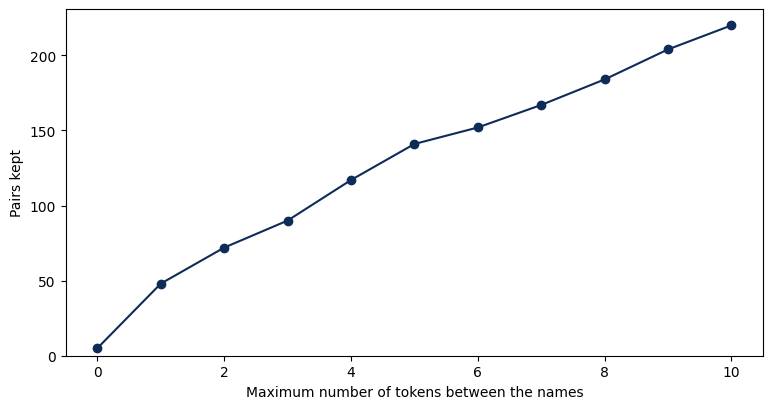

In [16]:
distances = range(11)
kept = [(pairs["gap"] <= n).sum() for n in distances]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(distances, kept, color=NAVY, marker="o")
ax.set_xlabel("Maximum number of tokens between the names")
ax.set_ylabel("Pairs kept")
ax.set_ylim(bottom=0)
plt.show()

About half of the pairs have more than 10 tokens between the names.

Choose **one change** to the starting rule by comparing the candidates on the number of pairs they keep and on the precision of their checked pairs. The candidates are:

- **Distance:** `pairs[pairs["gap"] <= n]` keeps the pairs with at most `n` tokens between the names.

- **Linking words:** `pairs[pairs["pattern"].isin([...])]` keeps the pairs with a pattern from a list, such as `LOC 's ORG` and `ORG in LOC`.

Compare the distance candidate for at least one value of `n`. For the linking-word candidate, start from the most frequent patterns of the pairs with at most 3 tokens between the names.

Choose the patterns in which the linking words state where an organization is based.

Label the checked pairs of each candidate that have no label yet.

The selected rule should satisfy two requirements:

- The precision of its 30 checked pairs should be **at least 0.70**.

- It should keep **at least 25 pairs** of the 420.

If more than one candidate meets both requirements, the one that keeps the most pairs is selected.

Then provide evidence for the selected rule:

- The number of pairs that each candidate keeps, and the most frequent patterns of the pairs with at most 3 tokens between the names.

- The labels of the checked pairs of each candidate and its precision.

- The cause of each wrong checked pair of the selected rule.

- The completed decision table.

The pairs that each candidate keeps are counted, with the most frequent patterns of the pairs with at most 3 tokens between the names:

In [17]:
# Count the pairs that each candidate keeps and display the most frequent patterns of the pairs with at most 3 tokens between the names.
for n in (1, 2, 3):
    print(f"gap of at most {n}:", (pairs["gap"] <= n).sum(), "pairs")
LINKS = ["LOC 's ORG", "ORG in LOC", "ORG of LOC", "ORG , LOC", "ORG headquarters in LOC", "ORG ) in LOC"]
print("linking words:", pairs["pattern"].isin(LINKS).sum(), "pairs")
pairs.loc[pairs["gap"] <= 3, "pattern"].value_counts().head(10)

gap of at most 1: 48 pairs
gap of at most 2: 72 pairs
gap of at most 3: 90 pairs
linking words: 33 pairs


pattern
LOC 's ORG                 13
ORG in LOC                  7
ORG , LOC                   5
ORG of LOC                  4
LOC ORG                     3
ORG , a LOC                 3
LOC , ORG                   2
ORG ) in LOC                2
ORG LOC                     2
ORG headquarters in LOC     2
Name: count, dtype: int64

The checked pairs of each candidate that have no label yet are displayed and labeled, and the precision of each candidate is calculated:

In [18]:
# Display the checked pairs of each candidate that have no label yet, label them, and calculate the precision of each candidate.
distance, linking = pairs[pairs["gap"] <= 1], pairs[pairs["pattern"].isin(LINKS)]
show(checked_pairs(distance).drop(index=list(labels), errors="ignore"))
show(checked_pairs(linking).drop(index=list(labels), errors="ignore"))
labels.update({86: 0, 359: 0, 388: 0, 40: 0, 41: 0, 221: 0, 201: 1, 31: 0, 411: 1, 324: 1, 321: 0, 127: 0, 46: 1, 402: 1,
               134: 1, 35: 0, 385: 1, 383: 0, 20: 0, 32: 0, 137: 0, 176: 1, 284: 0, 316: 1, 366: 1, 214: 1, 242: 1, 227: 1,
               56: 1, 72: 1, 351: 0, 113: 1, 368: 1, 283: 1, 168: 0, 282: 0, 159: 1, 117: 0, 156: 1, 222: 1, 226: 1, 99: 1,
               255: 1, 48: 1, 247: 0, 102: 1})
precision(distance, labels)
precision(linking, labels)

86: A [ORG Bank] [LOC Indonesia] spokeswoman confirmed the newspaper report but declined to give further details .

359: Representatives of the five nations making up the committee -- Israel , Lebanon , Syria , France and the United States -- will meet at 11 a.m. ( 0800 GMT ) in Naqoura , the coastal headquarters of [ORG the U.N. Interim Force] in [LOC Lebanon] ( UNIFIL ) .

388: The contract involved upgrading the flight data processing system at the Oceanic Control Centre in Prestwick in south west [LOC Scotland] for [ORG National Air Traffic Services Ltd] ( NATS ) , subsidiary of the Civil Aviation Authority .

40: The Redmond , Wash.-based company spent tens of millions of dollars promoting the product with stunts that included buying the entire print run of the Times of London and lighting [LOC New York 's] [ORG Empire State] building in a Windows color scheme .

41: Just who owns the copper is a question that has kept traders and industry analysts guessing since the metal was cha

The cause of each wrong checked pair of the linking-word candidate is stored, and the pairs of each cause are counted:

In [19]:
# Store the cause of each wrong checked pair of the selected rule and count the pairs of each cause.
causes.update({359: "entity error", 321: "entity error", 284: "entity error", 351: "entity error", 168: "entity error",
               282: "entity error", 117: "no relation", 247: "entity error"})
wrong = [number for number in checked_pairs(linking).index if labels[number] == 0]
pd.Series([causes[number] for number in wrong]).value_counts()

entity error    7
no relation     1
Name: count, dtype: int64

**Expected results:**

- **Distance:** at most 1, 2, and 3 tokens between the names keep about **48**, **72**, and **90** pairs. With at most 1 token, about 15 of the 30 checked pairs are correct, a precision of about **0.50**, which fails the first requirement.

- **Linking words:** the 6 patterns `LOC 's ORG`, `ORG in LOC`, `ORG of LOC`, `ORG , LOC`, `ORG headquarters in LOC`, and `ORG ) in LOC` keep about **33** pairs. About 22 of their 30 checked pairs are correct, a precision of about **0.73**, which meets both requirements.

- `LOC 's ORG` alone keeps about 13 pairs, which fails the second requirement.

- About 7 of the 8 wrong checked pairs of the linking-word candidate are entity errors, such as `First of Michigan Corp.` cut to `Michigan Corp.`. The remaining pair, `AOL in Europe`, has no relation.

Complete the decision table with one row for each candidate, including each value of `n` compared. In the **Rule** column, enter the value of `n` or the list of patterns, and in the **Decision** column, *Kept* or *Rejected*.

In the **Reason** column, support each decision with the number of pairs kept and the precision.

| Rule | Pairs | Precision | Decision | Reason |
|---|---|---|---|---|
| Starting rule | 420 | | | |
| Distance, `n` = | | | | |
| Linking words: | | | | |

## 5. Choosing the Number of Topics

### 5.1 Representing News Articles as Bags of Words

The topic model reads the 2,225 articles of `bbc` as bags of words over their lemmas, prepared in these steps:

- `lemmas()` keeps the alphabetic tokens of each processed article as lowercase lemmas, so that forms such as `films` and `film` are counted as one word.

- NLTK's English stop words are removed.

- `filter_extremes()` removes the lemmas found in fewer than 10 articles or in more than 30% of them, and the lemmas that remain form the vocabulary.

In [20]:
STOP = set(stopwords.words("english"))

def lemmas(doc):
    return [t.lemma_.lower() for t in doc if t.is_alpha and t.lower_ not in STOP and t.lemma_.lower() not in STOP]

articles = [lemmas(doc) for doc in nlp_spacy.pipe(bbc["text"], batch_size=64, disable=["parser", "ner"])]
dictionary = Dictionary(articles)
dictionary.filter_extremes(no_below=10, no_above=0.3)
corpus = [dictionary.doc2bow(article) for article in articles]
print(len(articles), "articles |", len(dictionary), "words in the vocabulary")

2225 articles | 4328 words in the vocabulary


The investigation uses these functions:

- `train(k, seed=42)` trains an LDA model with `k` topics, reading the whole corpus at each update, with 20 passes and `seed` as its random starting point.

- `coherence(model)` calculates the c_v of each topic from its 10 top words. It returns the c_v of the model, the average over its topics, and the c_v of each topic.

- `top_words(model, n=8)` returns a table with the `n` most probable words of each topic, 8 by default.

A model with 2 topics is trained, and its c_v and top words are displayed:

In [21]:
def train(k, seed=42):
    return LdaModel(corpus, num_topics=k, id2word=dictionary, chunksize=len(corpus), passes=20, iterations=400, random_state=seed)

def coherence(model):
    scores = CoherenceModel(model=model, texts=articles, dictionary=dictionary, coherence="c_v", topn=10, processes=1)
    return round(float(scores.get_coherence()), 3), [round(float(c), 3) for c in scores.get_coherence_per_topic()]

def top_words(model, n=8):
    return pd.DataFrame({f"Topic {k}": [word for word, _ in model.show_topic(k, n)] for k in range(model.num_topics)}).T

model_2 = train(2)
print(coherence(model_2))
top_words(model_2)

(0.425, [0.412, 0.437])


,0,1,2,3,4,5,6,7
Topic 0,government,play,labour,party,game,win,election,minister
Topic 1,us,use,film,company,firm,show,market,music


With only 2 topics, each topic combines several themes, such as politics and sport in Topic 0.

### 5.2 Selecting the Number of Topics for a News Archive

**Task:** An editor wants to organize a news archive with a list of topics, each named in a few words. Each topic should represent one theme, and no theme should appear in two topics.

**Corpus:** The corpus consists of the 2,225 BBC News articles as bags of words over the vocabulary. Their categories are not used to choose the setting.

The top words of each topic are read to identify the junk topics and the duplicate topics of each setting.

Choose the **number of topics** by comparing at least 3 of the settings 3, 4, 5, 6, 8, 10, 12, and 15 on their coherence and on a reading of their top words.

The selected setting should satisfy two requirements:

- The c_v of the model should be **at least 0.62**.

- The c_v of every topic should be **at least 0.50**, so that no topic is much less coherent than the others.

If none of the settings compared meets both requirements, compare further settings of the list until one does. Among the settings that meet both requirements, the one with no junk or duplicate topic is selected.

Then provide evidence for the selected setting:

- A plot of the c_v of the model and the lowest c_v of a topic against the number of topics.

- The 8 top words of each topic of each setting, with a name for each topic and the junk and duplicate topics marked in a Markdown cell.

- The completed decision table.

A model is trained for 5 of the settings, and its c_v and the lowest c_v of a topic are calculated:

In [22]:
# Train a model for each setting and calculate its c_v and the lowest c_v of a topic.
settings = [3, 4, 5, 10, 15]
models, rows = {}, []
for k in settings:
    models[k] = train(k)
    model_cv, topic_cv = coherence(models[k])
    rows.append({"topics": k, "c_v of the model": model_cv, "lowest c_v of a topic": min(topic_cv)})
results = pd.DataFrame(rows).set_index("topics")
results

,c_v of the model,lowest c_v of a topic
topics,,
3,0.486,0.329
4,0.634,0.535
5,0.646,0.520
10,0.613,0.381
15,0.689,0.461


The c_v of the model and the lowest c_v of a topic are plotted against the number of topics, with the two requirements as dashed lines:

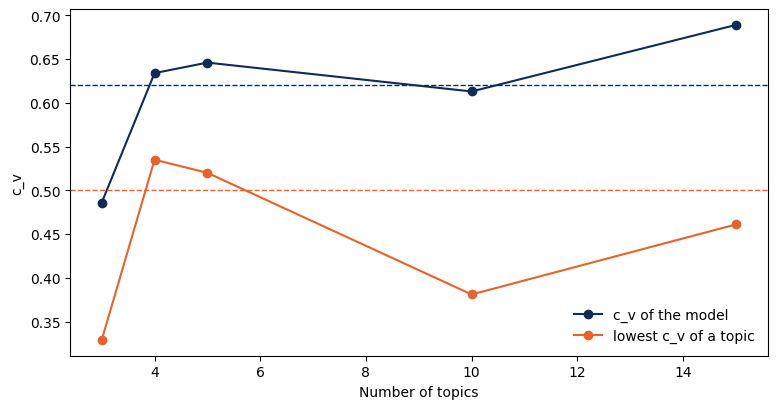

In [23]:
# Plot the c_v of the model and the lowest c_v of a topic against the number of topics.
ax = results.plot(figsize=(9, 4.5), color=[NAVY, ORANGE], marker="o")
ax.axhline(0.62, color=NAVY, linestyle="--", linewidth=1)
ax.axhline(0.50, color=ORANGE, linestyle="--", linewidth=1)
ax.set_xlabel("Number of topics")
ax.set_ylabel("c_v")
ax.legend(loc="lower right", frameon=False)
plt.show()

The top words of each model are displayed:

In [24]:
# Display the top words of each model and name each topic.
for k in settings:
    print(f"{k} topics")
    display(top_words(models[k]))

3 topics


,0,1,2,3,4,5,6,7
Topic 0,game,play,win,player,england,back,club,team
Topic 1,us,film,company,sale,market,firm,rise,include
Topic 2,use,government,party,service,labour,election,work,technology


4 topics


,0,1,2,3,4,5,6,7
Topic 0,game,play,win,player,england,back,team,club
Topic 1,film,music,award,star,show,include,us,top
Topic 2,government,party,labour,election,minister,blair,use,plan
Topic 3,us,company,firm,use,market,technology,high,month


5 topics


,0,1,2,3,4,5,6,7
Topic 0,game,play,win,player,england,back,club,match
Topic 1,film,star,award,us,show,include,director,actor
Topic 2,government,labour,party,election,minister,blair,plan,brown
Topic 3,us,company,firm,market,rise,share,month,price
Topic 4,use,music,game,technology,mobile,phone,like,user


10 topics


,0,1,2,3,4,5,6,7
Topic 0,us,country,government,eu,china,case,state,uk
Topic 1,film,star,award,actor,director,include,us,yukos
Topic 2,labour,party,government,election,minister,blair,plan,brown
Topic 3,company,firm,share,us,bank,deal,market,business
Topic 4,use,search,work,site,user,many,online,find
Topic 5,market,rise,growth,technology,high,sale,rate,economy
Topic 6,dvd,patent,ebbers,high,law,england,bath,definition
Topic 7,phone,mobile,use,service,network,mail,firm,user
Topic 8,play,game,win,player,england,back,match,team
Topic 9,game,music,show,song,band,play,album,top


15 topics


,0,1,2,3,4,5,6,7
Topic 0,law,government,case,eu,uk,right,court,us
Topic 1,us,company,oil,sale,dollar,firm,yukos,president
Topic 2,labour,election,government,party,blair,minister,brown,plan
Topic 3,company,firm,share,market,offer,deal,executive,us
Topic 4,use,site,software,user,computer,net,search,virus
Topic 5,game,technology,use,digital,player,video,high,device
Topic 6,england,wales,rugby,six,ireland,nations,robinson,france
Topic 7,mobile,phone,service,network,use,firm,call,system
Topic 8,game,win,play,player,team,back,club,side
Topic 9,music,song,band,album,number,chart,record,single


**Expected results:**

- The c_v values should be about:

| Topics | 3 | 4 | 5 | 6 | 8 | 10 | 12 | 15 |
|---|---|---|---|---|---|---|---|---|
| c_v of the model | 0.486 | 0.634 | 0.646 | 0.655 | 0.615 | 0.613 | 0.659 | 0.689 |
| Lowest c_v of a topic | 0.329 | 0.535 | 0.520 | 0.492 | 0.484 | 0.381 | 0.475 | 0.461 |

- Only the settings of 4 and 5 topics meet both requirements. The model with 15 topics has the highest c_v, but the lowest c_v of a topic is below 0.50.

- With 3 topics, business and entertainment should share one topic, and politics and technology another, so both are junk topics.

- With 4 topics, business and technology should share one topic (`us, company, firm, use, market, technology`), a junk topic.

- With 5 topics, each topic should represent one theme: sport, film and entertainment, politics, business, and technology. The reading therefore selects 5 topics.

- With 10 topics, one topic should combine unrelated words such as `dvd`, `patent`, and `ebbers`, a junk topic. Film and music should become separate topics, as should companies and the economy, which may be accepted as separate themes.

- With 15 topics, sport should be split into topics on rugby, football, and tennis, which may be marked as duplicates or as narrow themes, and one topic (`show, bbc, tv, country, child`) should have no shared theme.

Complete the decision table with one row for each setting compared, and *Kept* or *Rejected* in the **Decision** column.

In the **Junk or duplicate topics** column, give the numbers of the junk and duplicate topics, or *None*. In the **Reason** column, support each decision with the c_v values and the reading of the top words.

| Setting | c_v of the model | Lowest c_v of a topic | Junk or duplicate topics | Decision | Reason |
|---|---|---|---|---|---|
| | | | | | |
| | | | | | |
| | | | | | |

## Exercises

### Exercise 1: Entity Errors Behind the Pairs

A pair can only be correct if spaCy has recognized both of its names correctly.

For each pair of the starting rule, check whether the organization matches a **gold ORG entity** and the location a **gold LOC entity**. A match requires the same start and end token positions.

Display:

- The number of the 420 pairs in which both names match a gold entity.

- The number of pairs in which the organization matches no gold ORG entity.

- The number of pairs in which the location matches no gold LOC entity. A pair may be counted in both.

In [25]:
# Count the pairs whose organization and location match gold entities, and the pairs with each kind of mismatch.
org_ok = pairs.apply(lambda row: (*row["org_span"], "ORG") in gold[row["sentence"]], axis=1)
loc_ok = pairs.apply(lambda row: (*row["loc_span"], "LOC") in gold[row["sentence"]], axis=1)
print("both names match a gold entity:", (org_ok & loc_ok).sum(), "of", len(pairs))
print("organization without a match:", (~org_ok).sum())
print("location without a match:", (~loc_ok).sum())

both names match a gold entity: 226 of 420
organization without a match: 140
location without a match: 88


**Expected result:** Both names match a gold entity in about **226** of the 420 pairs.

In about **140** pairs the organization matches no gold ORG entity, and in about **88** the location matches no gold LOC entity. These names have other boundaries or another type in the gold tags, or are not marked as entities at all, as for `**`, a list mark at the start of some sentences.

### Exercise 2 (Extension): Training a Custom Entity Type

**JOB_TITLE** is a custom entity type for the position that a person holds, such as `spokesman` or `chief executive`.

The first 50 sentences of the corpus that contain at least one of 12 job-title words are used, the first 35 for training and the remaining 15 for evaluation. They are displayed with their numbers:

In [26]:
TITLE_WORDS = r"\b(?:president|chairman|analyst|spokesman|spokeswoman|economist|director|executive|manager|minister|governor|officer)\b"
title_sentences = news.loc[news["tokens"].str.contains(TITLE_WORDS, case=False), "tokens"].head(50).tolist()
print(len(title_sentences), "sentences")
for number, text in enumerate(title_sentences):
    print(number, text)

50 sentences
0 A spokesman for the group said the meeting " signals a new level of cooperation between Mujahideen Khalq and the Iranian Kurdish oppositions " .
1 -- Lehman analyst Blake Bath started Southern New England Telecommunciations Corp with an outperform rating , his office said .
2 Best Products Co Chairman and Chief Executive Daniel Levy said Thursday he expected the company 's second-quarter results to be similar to the $ 34.6 million loss posted in the first quarter .
3 The chairman of national carrier EgyptAir on Thursday blamed the control tower at Istanbul airport for the EgyptAir plane accident .
4 Martin Brooks , president of Miss Universe Inc , said he spoke with Machado to assure her that organisers were not putting pressure on her .
5 The Reserve bank of India governor C. Rangarajan said on Thursday that he expected the cash reserve ratio ( CRR ) maintained by banks to be reduced over the medium term .
6 The Reserve Bank of India Governor Chakravarty Rangarajan said

A job title is annotated with the preceding words that belong to the position, such as `chief`, `vice`, `senior`, or `Finance`. The name of the organization and a following phrase with `of` are not part of it.

**Example:** In `ING analyst Steven Vrolijk`, the job title is `analyst`. The phrase `executive vice president and chief financial officer` contains 2 job titles, `executive vice president` and `chief financial officer`.

`annotate(text, phrases, label="JOB_TITLE")` converts the job titles of a sentence into character positions, the form that `Example.from_dict()` requires. Its parameters are:

- `text`: the sentence to annotate, such as `title_sentences[2]`.

- `phrases`: the job titles exactly as they are written in the sentence, such as `["Chairman", "Chief Executive"]`. Every occurrence of each phrase is annotated, except one that falls inside a longer annotated phrase.

- `label` (default `"JOB_TITLE"`): the entity type of the annotated phrases.

In [27]:
def annotate(text, phrases, label="JOB_TITLE"):
    spans = []
    for phrase in sorted(phrases, key=len, reverse=True):
        for m in re.finditer(r"\b" + re.escape(phrase) + r"\b", text):
            if all(m.end() <= start or m.start() >= end for start, end, _ in spans):
                spans.append((m.start(), m.end(), label))
    return sorted(spans)

print(annotate(title_sentences[2], ["Chairman", "Chief Executive"]))

[(17, 25, 'JOB_TITLE'), (30, 45, 'JOB_TITLE')]


`train_titles(annotations, passes=30)` trains a separate copy of the pipeline on the first 35 sentences, in four steps:

- It loads a new copy of `en_core_web_sm`, so that `nlp_spacy` is not changed, and adds the new entity type with `add_label("JOB_TITLE")`.

- It converts each training sentence and its entities into a training example with `Example.from_dict()`.

- `nlp.resume_training()` returns an optimizer that continues training from the existing weights of the model.

- With only the entity recognizer enabled by `nlp.select_pipes(enable=["ner"])`, `nlp.update(batch, sgd=optimizer, drop=0.2)` updates it on batches of 8 shuffled sentences. `drop=0.2` switches off a random 20% of the network's values at each update, which reduces overfitting to the 35 sentences.

Its parameters are:

- `annotations`: the character positions of the job titles of the 50 sentences, one list for each sentence, as returned by `annotate()`. Only the first 35 are used for training.

- `passes` (default 30): the number of complete passes through the training sentences.

`fix_random_seed(0)` and `random.seed(0)` fix the starting point, so that the same annotations give the same model.

In [28]:
def train_titles(annotations, passes=30):
    fix_random_seed(0)
    random.seed(0)
    nlp = spacy.load("en_core_web_sm")
    nlp.get_pipe("ner").add_label("JOB_TITLE")
    train = [Example.from_dict(nlp.make_doc(t), {"entities": a}) for t, a in zip(title_sentences[:35], annotations[:35])]
    optimizer = nlp.resume_training()
    with nlp.select_pipes(enable=["ner"]):
        for _ in range(passes):
            random.shuffle(train)
            for batch in minibatch(train, size=8):
                nlp.update(batch, sgd=optimizer, drop=0.2)
    return nlp

Annotate the job titles of the **50 sentences** as a list with one list of phrases for each sentence. Convert the annotations with `annotate()`, then train a model with `train_titles()`.

Convert the 15 held-out sentences into examples with `Example.from_dict()`, then evaluate the model on them with `nlp.evaluate()`, which returns the scores of each entity type under the key `"ents_per_type"`.

Display:

- The F1 of JOB_TITLE on the 15 held-out sentences.

- The F1 of ORG on the company news, calculated with `entity_scores(process(nlp))`, before and after training.

Add the entities that `nlp_spacy` identifies in each training sentence to its annotations, except any entity that overlaps an annotated job title. Train again, so that the recognizer keeps its original types.

Evaluate the new model on the same 15 held-out sentences.

Display:

- The F1 of JOB_TITLE on the 15 held-out sentences and the F1 of ORG on the company news after this training.

In [29]:
# Annotate the 50 sentences, train a new copy of the pipeline on the first 35, and display the F1 of JOB_TITLE on the last 15 and the F1 of ORG before and after training.
titles = [["spokesman"], ["analyst"], ["Chairman", "Chief Executive"], ["chairman"], ["president"], ["governor"], ["Governor"],
          ["chairman"], [], ["president"], ["analyst"], ["analyst"], ["analyst"], ["analyst"],
          ["Public Service , Labour and Social Welfare Minister"], ["acting chairman", "president", "chairman"],
          ["vice president", "senior engineer"], ["ministers", "governor"], ["senior vice president"],
          ["president", "executive vice president", "chief financial officer"], ["spokesman"], ["spokesman"],
          ["head", "President"], ["analyst"], ["executive board chairman"], ["spokesman"], ["chief executive"], ["analyst"],
          ["spokeswoman"], ["analyst"], ["president"], ["spokesman"], ["finance director"], ["fund manager"],
          ["president", "chief operating officer"], ["spokeswoman"], ["governor"], ["director"], ["chief executive"],
          ["analyst"], ["managing director"], ["Chairman"], ["spokesman"], ["director"], ["foreign minister"],
          ["Finance Minister"], ["president"], ["spokesman"], ["general manager"], ["Finance Minister"]]
annotations = [annotate(text, phrases) for text, phrases in zip(title_sentences, titles)]
nlp_titles = train_titles(annotations)
held_out = [Example.from_dict(nlp_titles.make_doc(t), {"entities": a}) for t, a in zip(title_sentences[35:], annotations[35:])]
print("JOB_TITLE on the held-out sentences:", {k: round(v, 3) for k, v in nlp_titles.evaluate(held_out)["ents_per_type"]["JOB_TITLE"].items()})
print("ORG F1 before training:", scores.loc["ORG", "F1"])
print("ORG F1 after training:", entity_scores(process(nlp_titles)).loc["ORG", "F1"])

JOB_TITLE on the held-out sentences: {'p': 0.8, 'r': 0.8, 'f': 0.8}
ORG F1 before training: 0.631
ORG F1 after training: 0.0


**Expected results:**

- The F1 of JOB_TITLE on the 15 held-out sentences should be about **0.8**.

- The F1 of ORG should fall from about **0.631** to about **0**. The training annotations contain only job titles, so the organizations in them are treated as not entities, and the recognizer learns to leave organizations unlabeled.

In [30]:
# Add the entities of the original pipeline to the annotations of the training sentences, train again, and display both F1 values.
def with_original(text, spans):
    combined = list(spans)
    for ent in nlp_spacy(text).ents:
        if all(ent.end_char <= start or ent.start_char >= end for start, end, _ in combined):
            combined.append((ent.start_char, ent.end_char, ent.label_))
    return sorted(combined)

nlp_both = train_titles([with_original(t, a) for t, a in zip(title_sentences, annotations)])
print("JOB_TITLE on the held-out sentences:", {k: round(v, 3) for k, v in nlp_both.evaluate(held_out)["ents_per_type"]["JOB_TITLE"].items()})
print("ORG F1 after training:", entity_scores(process(nlp_both)).loc["ORG", "F1"])

JOB_TITLE on the held-out sentences: {'p': 0.769, 'r': 0.667, 'f': 0.714}
ORG F1 after training: 0.636


**Expected results, with the entities identified by `nlp_spacy` added:**

- The F1 of JOB_TITLE on the held-out sentences should be about **0.7**.

- The F1 of ORG should be about **0.64**, close to its value of about 0.631 before training.

### Exercise 3 (Extension): Decoding a Tag Sequence

`emission` and `transition` contain constructed CRF scores for the tokens of `Bahrain Polytechnic`, with 2 candidate tags for each token.

In [31]:
emission = {"Bahrain": {"B-LOC": 1.2, "B-ORG": 1.0}, "Polytechnic": {"I-ORG": 1.5, "O": 0.4}}
transition = {("B-LOC", "I-ORG"): -3.0, ("B-LOC", "O"): 0.5, ("B-ORG", "O"): 0.2, ("B-ORG", "I-ORG"): 1.0}
print(len(transition), "tag sequences")

4 tag sequences


The total score of a tag sequence, where $y_1$ is the tag of `Bahrain` and $y_2$ the tag of `Polytechnic`, is:

$$\text{total}(y_1, y_2) = \text{emission}(\text{Bahrain}, y_1) + \text{emission}(\text{Polytechnic}, y_2) + \text{transition}(y_1, y_2)$$

Display:

- The total score of each tag sequence.

- The tag with the highest emission score for each token, taken on its own.

- The tag sequence with the highest total score.

In [32]:
# Calculate the total of each tag sequence, the tag of each token with the highest emission score, and the sequence with the highest total.
totals = {(first, second): emission["Bahrain"][first] + emission["Polytechnic"][second] + transition[(first, second)]
          for first, second in transition}
for sequence, total in totals.items():
    print(sequence, round(total, 1))
print("highest emission score for each token:", [max(candidates, key=candidates.get) for candidates in emission.values()])
print("highest total:", max(totals, key=totals.get))

('B-LOC', 'I-ORG') -0.3
('B-LOC', 'O') 2.1
('B-ORG', 'O') 1.6
('B-ORG', 'I-ORG') 3.5
highest emission score for each token: ['B-LOC', 'I-ORG']
highest total: ('B-ORG', 'I-ORG')


**Expected results:**

- The total scores are **−0.3** for `B-LOC`, `I-ORG`, **2.1** for `B-LOC`, `O`, **1.6** for `B-ORG`, `O`, and **3.5** for `B-ORG`, `I-ORG`.

- Choosing the highest emission score for each token on its own gives `B-LOC` followed by `I-ORG`, a sequence that BIO does not allow. The transition score of −3.0 gives this sequence the lowest total score, so the CRF does not select it.

- The CRF selects `B-ORG` followed by `I-ORG` because this sequence has the highest total score, which identifies `Bahrain Polytechnic` as one organization.

### Exercise 4 (Extension): A Second Random Starting Point

Train the model of the **selected setting** again with `seed=1`, then read the top words of each topic.

Display:

- The 8 top words of each topic, with a name for each topic.

- Any junk or duplicate topics.

In a Markdown cell, explain what the result shows about choosing the number of topics from a single training run.

In [33]:
# Train the selected setting again with seed=1 and display its top words.
model_seed_1 = train(5, seed=1)
print(coherence(model_seed_1))
top_words(model_seed_1)

(0.607, [0.624, 0.667, 0.579, 0.552, 0.612])


,0,1,2,3,4,5,6,7
Topic 0,england,game,win,half,back,play,ireland,set
Topic 1,government,labour,party,election,minister,country,blair,plan
Topic 2,company,firm,us,share,use,sale,market,site
Topic 3,film,music,use,game,mobile,technology,phone,show
Topic 4,play,win,game,player,club,think,team,old


**Expected results:**

- With 5 topics and `seed=1`, 2 topics should represent sport (`england, game, win, half, back, play, ireland, set` and `play, win, game, player, club, think, team, old`), and another should combine film and technology (`film, music, use, game, mobile, technology, phone, show`).

- The c_v of the model should fall to about **0.607**, below the required 0.62.

- A choice made from a single run can therefore depend on its random starting point. The selected setting is checked with a second seed before it is used.